# 126 · Demonstrations that don't waste your time: coverage beats volume

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse import TableTop, ScriptedExpert, evaluate
from vlacourse.features import privileged_obs, PRIV_DIM

torch.set_num_threads(4)
FULL = [[0.35, 0.65], [-0.25, 0.25]]
NARROW = [[0.45, 0.55], [-0.08, 0.08]]

def demos(n, workspace, seed):
    env = TableTop(cameras=(), seed=seed, workspace=workspace, task_types=("pick", "place"))
    X, Y = [], []
    for ep in range(n):
        env.reset(seed=seed + ep); ex = ScriptedExpert(env, seed=ep); done = False
        while not done:
            X.append(privileged_obs(env)); a = ex.act(); Y.append(a); _, _, done, _ = env.step(a)
    return np.array(X), np.array(Y)

def fit(X, Y, epochs=60):
    torch.manual_seed(0); st = (X.mean(0), X.std(0) + 1e-6, Y.mean(0), Y.std(0) + 1e-6)
    net = nn.Sequential(nn.Linear(PRIV_DIM, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 7)); opt = torch.optim.Adam(net.parameters(), 1e-3)
    Xn, Yn = torch.tensor((X - st[0]) / st[1], dtype=torch.float32), torch.tensor((Y - st[2]) / st[3], dtype=torch.float32)
    for _ in range(epochs):
        for idx in torch.randperm(len(Xn)).split(256):
            loss = ((net(Xn[idx]) - Yn[idx]) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
    return net, st

class P:
    def __init__(self, env, net, st):
        self.env, self.net, self.st = env, net, st
    def act(self, obs):
        with torch.no_grad():
            a = self.net(torch.tensor((privileged_obs(self.env) - self.st[0]) / self.st[1], dtype=torch.float32)).numpy() * self.st[3] + self.st[2]
        a[6] = float(a[6] > 0.5); return a

In [2]:
test_env = TableTop(cameras=(), seed=0, workspace=FULL, task_types=("pick", "place"))
rows, pols = {}, {}
for name, n, ws in [("narrow layouts, 40 demos", 40, NARROW), ("narrow layouts, 160 demos", 160, NARROW), ("full coverage, 40 demos", 40, FULL), ("full coverage, 160 demos", 160, FULL)]:
    net, st = fit(*demos(n, ws, seed=1000))
    pols[name] = P(test_env, net, st)
    rows[name] = evaluate(test_env, pols[name], n_episodes=60, seed=70_000)
    print(f"{name:28s} success on the FULL workspace: {rows[name]['success']:.2f} CI [{rows[name]['ci'][0]:.2f}, {rows[name]['ci'][1]:.2f}]")

narrow layouts, 40 demos     success on the FULL workspace: 0.02 CI [0.00, 0.09]


narrow layouts, 160 demos    success on the FULL workspace: 0.03 CI [0.01, 0.11]


full coverage, 40 demos      success on the FULL workspace: 0.22 CI [0.13, 0.34]


full coverage, 160 demos     success on the FULL workspace: 0.62 CI [0.49, 0.73]


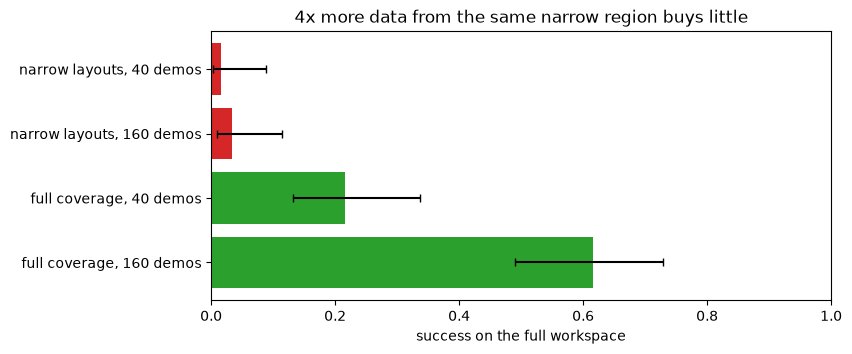

In [3]:
names = list(rows); s = np.array([rows[n]["success"] for n in names]); ci = np.array([rows[n]["ci"] for n in names])
plt.figure(figsize=(8, 3.5)); plt.barh(names, s, xerr=[s - ci[:, 0], ci[:, 1] - s], capsize=3, color=["tab:red", "tab:red", "tab:green", "tab:green"])
plt.xlim(0, 1); plt.gca().invert_yaxis(); plt.xlabel("success on the full workspace"); plt.title("4x more data from the same narrow region buys little"); plt.show()

### Watch it: 160 narrow demos vs 160 demos spread over the table
Same amount of data, same episode on the full workspace.

In [4]:
from vlacourse import showcase as sc
a, b = "full coverage, 160 demos", "narrow layouts, 160 demos"
sc.compare(test_env, {b: pols[b], a: pols[a]}, seed=sc.pick_seed(rows[a], rows[b], 70_000), title="126 narrow vs full coverage")

126 narrow vs full coverage: narrow layouts, 160 demos: failed | full coverage, 160 demos: success


[False, True]